---

# CHAPTER 1: SIMPLE LINEAR REGRESSION MODELLING

---

<br><br>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

<br><br>

---

## 1. A Tale of two variables

In [2]:
df1 = pd.read_csv('Resources/taiwan_real_estate2.csv')
df1.head()

,dist_to_mrt_m,n_convenience,house_age_years,price_twd_msq
0,84.87882,10,30 to 45,11.467474
1,306.59470,9,15 to 30,12.768533
2,561.98450,5,0 to 15,14.311649
3,561.98450,5,0 to 15,16.580938
4,390.56840,5,0 to 15,13.040847


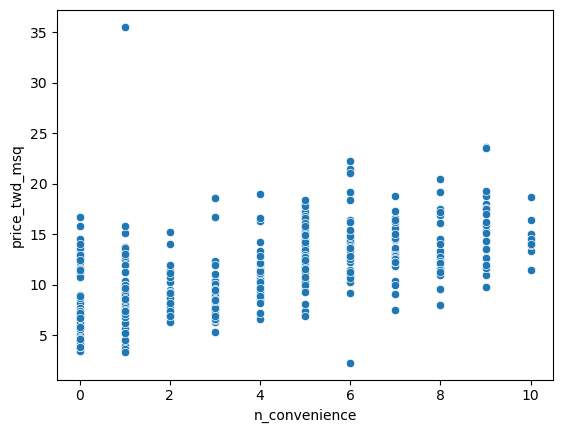

In [3]:
# Using taiwan_real_estate, draw a scatter plot of "price_twd_msq" (y-axis) versus "n_convenience" (x-axis).
sns.scatterplot(data=df1, x='n_convenience', y='price_twd_msq')
plt.show()

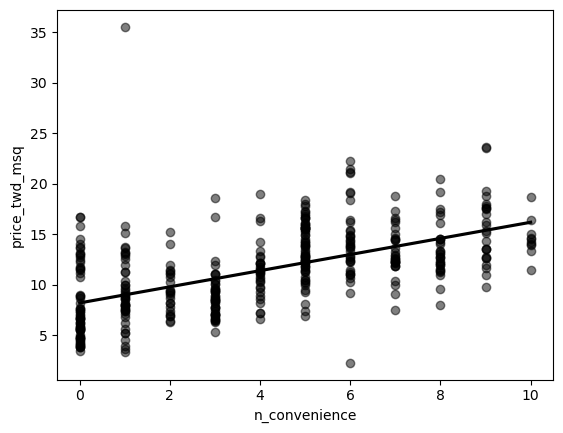

In [8]:
# Draw a trend line on the scatter plot of price_twd_msq vs. n_convenience
sns.regplot(data=df1, x='n_convenience', 
            y='price_twd_msq', ci=None, 
            color='k', scatter_kws={'alpha':0.5})
plt.show()

>---
>
>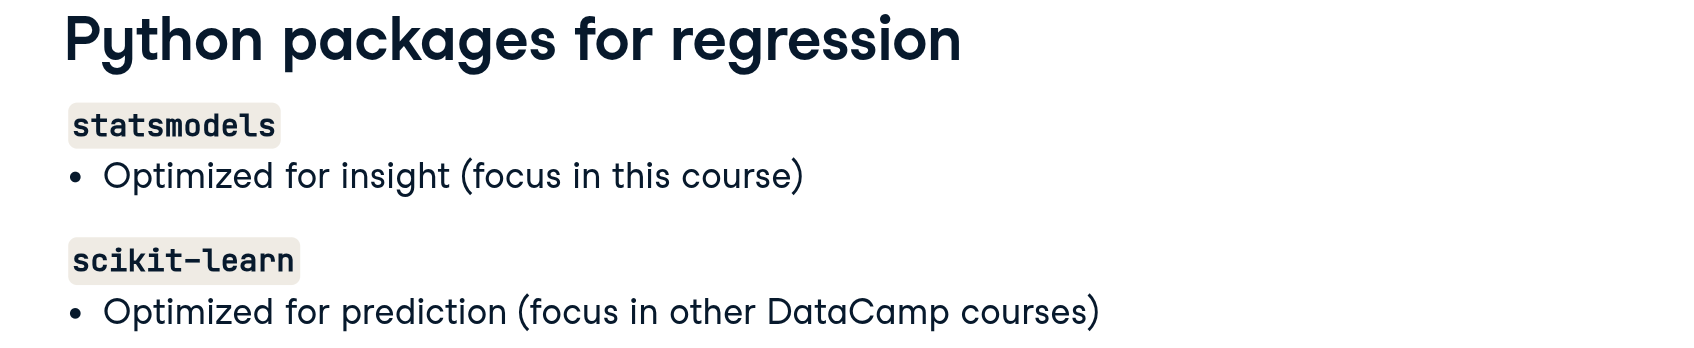
>
>---

<br><br>

---

## 2. Fitting a Linear Regression

In [9]:
# To run a Linear Regression Model we need to import OLS from statsmodels, as follows...
from statsmodels.formula.api import ols

>---
>
>ols('y_values' (response) ~ 'x_values' (explanatory), data=df (dataset))
>
>---

In [10]:
# Create the model object
lr_model = ols('price_twd_msq ~ n_convenience', data=df1)

# Fit the model
lr_fit_model = lr_model.fit()

# Print the parameters of the fitted model
lr_fit_model.params

Intercept        8.224237
n_convenience    0.798080
dtype: float64

<span style='color:orange'>
    
>---
>
>**The model had an Intercept coefficient of 8.2242. What does this mean?**
>
>   - On average, a house with zero convenience stores nearby had a price of 8.2242 TWD per square meter.
>
>---
>
>**The model had an n_convenience coefficient of 0.7981. What does this mean?**
>
>   - If you increase the number of nearby convenience stores by one, then the expected increase in house price is 0.7981 TWD per square meter.



<br><br>

---

## 3. Categorical Explanatory Variables

In [11]:
# Lets take a look at our data...
df1.head()

,dist_to_mrt_m,n_convenience,house_age_years,price_twd_msq
0,84.87882,10,30 to 45,11.467474
1,306.59470,9,15 to 30,12.768533
2,561.98450,5,0 to 15,14.311649
3,561.98450,5,0 to 15,16.580938
4,390.56840,5,0 to 15,13.040847


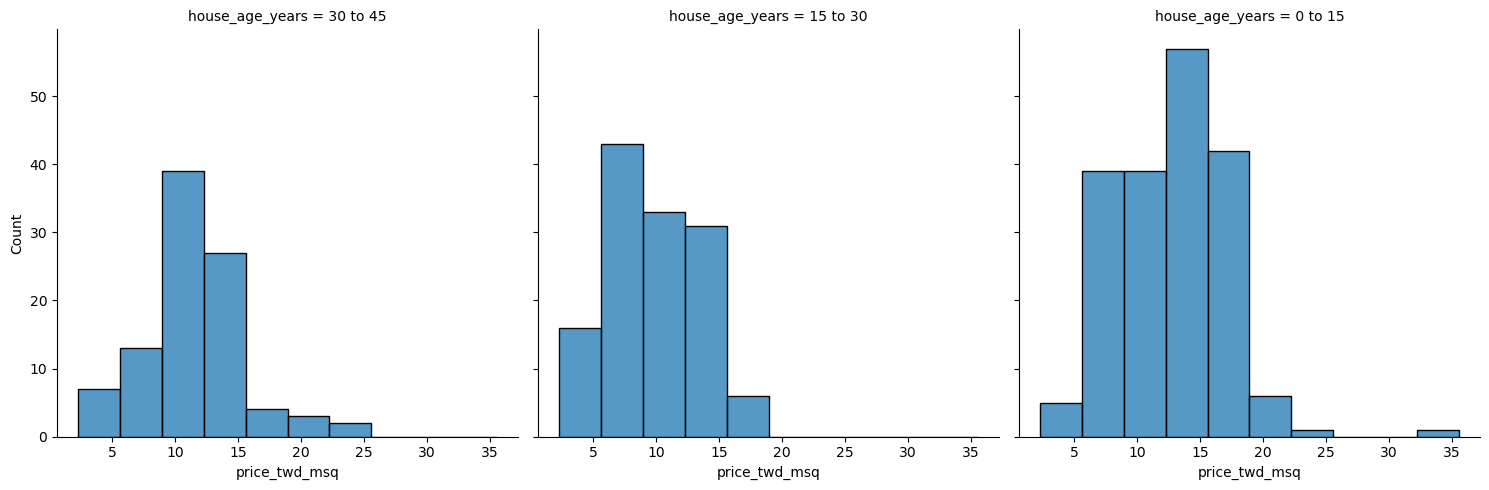

In [12]:
# Histograms of price_twd_msq with 10 bins, split by the age of each house
sns.displot(data=df1, x='price_twd_msq', bins=10,
            col='house_age_years')
plt.show()

<br><br>

>---
>
>A good way to explore categorical variables further is to calculate summary statistics for each category.
>For example, you can calculate the `mean` and `median` of your **response variable**, `grouped by a categorical variable`. As such, you can compare each category in more detail.
>
>Here, you'll look at grouped means for the house prices in the Taiwan real estate dataset. This will help you understand the output of a linear regression with a categorical variable.
>
>---

In [20]:
# Calculate the mean of price_twd_msq, grouped by house age
mean_price_by_age = df1.groupby('house_age_years', as_index=False)['price_twd_msq'].mean()

print(" - Make a mental note of the results, as they'll feature in the next exercise too.\n")

mean_price_by_age

 - Make a mental note of the results, as they'll feature in the next exercise too.



,house_age_years,price_twd_msq
0,0 to 15,12.637471
1,15 to 30,9.876743
2,30 to 45,11.393264


In [22]:
# Create the model, fit it
mdl_price_vs_age = ols('price_twd_msq ~ house_age_years', data=df1).fit()

# Print the parameters of the fitted model
mdl_price_vs_age.params

Intercept                      12.637471
house_age_years[T.15 to 30]    -2.760728
house_age_years[T.30 to 45]    -1.244207
dtype: float64

In [23]:
# Update the model formula to remove the intercept
mdl_price_vs_age_0 = ols('price_twd_msq ~ house_age_years + 0', data=df1).fit()

# Print the parameters of the fitted model
mdl_price_vs_age_0.params

house_age_years[0 to 15]     12.637471
house_age_years[15 to 30]     9.876743
house_age_years[30 to 45]    11.393264
dtype: float64

<span style='color:orange'>

>---
>
>The coefficients of the model are just the means of each category we've calculated previously.
>
>---

<br>